# Estudo de Caso 5.X1 — Profundidade Normal em Canal Trapezoidal: Equação de Manning com Método de Brent

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 5 — Hidrodinâmica de Canais Abertos |
| **Nível** | Graduação |
| **Tempo estimado** | 45 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Método de Brent para equação não-linear |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 5; Chow (1959), Cap. 5; Henderson (1966), Cap. 2 |

---

## 📋 Resumo

Determinamos a profundidade normal ($h_n$) de um canal trapezoidal utilizando a equação de Manning. Como a equação é não-linear em $h$ (aparece na área e no raio hidráulico), resolvemos numericamente pelo método de Brent. O notebook inclui a definição da geometria trapezoidal, a implementação da equação de Manning, a solução numérica iterativa, a visualização da curva vazão-profundidade e a análise de sensibilidade aos parâmetros hidráulicos.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Calcular** propriedades geométricas de seção trapezoidal (área, perímetro, raio hidráulico)
2. **Aplicar** a equação de Manning para determinar a vazão em regime uniforme
3. **Resolver** equações não-lineares pelo método de Brent com bracketing adequado
4. **Interpretar** a relação vazão-profundidade e identificar a solução única
5. **Analisar** a sensibilidade da profundidade normal à rugosidade, declividade e vazão
6. **Avaliar** a existência e unicidade da solução pelo teorema do valor intermediário

---
## ⚙️ Seção 0: Configuração Inicial

In [17]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Forçar fonte com suporte completo a glifos Unicode/LaTeX
plt.rcParams['font.family'] = 'DejaVu Sans'

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | SciPy {__import__("scipy").__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | SciPy 1.17.1


---
## 🌊 Seção 1: Parâmetros do Canal Trapezoidal

### Contexto Físico

Em regime uniforme, a profundidade da lâmina d'água em um canal aberto é chamada **profundidade normal** ($h_n$). Ela é determinada pelo equilíbrio entre a força gravitacional (que impulsiona o escoamento) e a resistência ao escoamento (atrito com as paredes e o fundo).

A equação de Manning relaciona a vazão $Q$ com a profundidade $h$:

$$Q = \frac{1}{n} A(h) R_h(h)^{2/3} S_0^{1/2}$$

Como $A$ e $R_h$ dependem de $h$ de forma não-linear, a equação é **implícita** em $h$: não existe fórmula fechada para $h_n$ em seções trapezoidais.

> 💡 **Observação:** A profundidade normal é um conceito fundamental em hidráulica de canais. Ela define a condição de referência para classificação de perfis de remanso e projeto de canais.

### Geometria Trapezoidal

Para um canal trapezoidal com largura de fundo $b$ e talude $m$ (H:V):

- **Área molhada:** $A = (b + mh)h$
- **Perímetro molhado:** $P = b + 2h\sqrt{1 + m^2}$
- **Raio hidráulico:** $R_h = A/P$
- **Largura superficial:** $B = b + 2mh$

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| Largura de fundo | $b$ | 3,0 | m |
| Talude (H:V) | $m$ | 1,5 | – |
| Coeficiente de Manning | $n$ | 0,025 | s/m^(1/3) |
| Declividade do fundo | $S_0$ | 10⁻³ | m/m |
| Vazão de projeto | $Q$ | 5,0 | m³/s |

In [2]:
# ============================================================
# PARÂMETROS DO CANAL TRAPEZOIDAL
# ============================================================

# Geometria
b = 3.0           # Largura de fundo [m]
m = 1.5           # Talude (H:V) [-]

# Propriedades hidráulicas
n_manning = 0.025   # Coeficiente de Manning [s/m^(1/3)]
S0 = 1.0e-3         # Declividade do fundo [m/m]
Q = 5.0             # Vazão de projeto [m³/s]

# Intervalo de busca para h_n
h_min = 0.01        # Limite inferior [m]
h_max = 5.0         # Limite superior [m]

print('📏 Parâmetros do Canal Trapezoidal:')
print(f'  • Largura de fundo: b = {b} m')
print(f'  • Talude: m = {m} (H:V)')
print(f'  • Manning: n = {n_manning} s/m^(1/3)')
print(f'  • Declividade: S₀ = {S0:.1e} m/m')
print(f'  • Vazão: Q = {Q} m³/s')
print(f'  • Intervalo de busca: [{h_min}, {h_max}] m')

📏 Parâmetros do Canal Trapezoidal:
  • Largura de fundo: b = 3.0 m
  • Talude: m = 1.5 (H:V)
  • Manning: n = 0.025 s/m^(1/3)
  • Declividade: S₀ = 1.0e-03 m/m
  • Vazão: Q = 5.0 m³/s
  • Intervalo de busca: [0.01, 5.0] m


---
## 🔬 Seção 2: Verificação — Existência e Unicidade da Solução

Antes de aplicar o método de Brent, verificamos:

1. **Existência de raiz:** $f(h_{min})$ e $f(h_{max})$ devem ter sinais opostos
2. **Unicidade:** $Q(h)$ deve ser monótona crescente (garante solução única)

> 📖 **Referência:** Chow (1959), Cap. 5; Lugon Jr. et al. (2026), Cap. 5, Seção 5.2.

In [3]:
# ============================================================
# VERIFICAÇÃO — EXISTÊNCIA E UNICIDADE
# ============================================================

def geometria_trapezoidal(b, m, h):
    """
    Calcula propriedades geométricas de seção trapezoidal.

    Parameters
    ----------
    b : float
        Largura de fundo [m].
    m : float
        Inclinação do talude (H:V) [-].
    h : float
        Profundidade da lâmina d'água [m].

    Returns
    -------
    dict
        {'A': área [m²], 'P': perímetro [m],
         'Rh': raio hidráulico [m], 'B': largura superficial [m]}

    Notes
    -----
    A = (b + m*h) * h
    P = b + 2*h*sqrt(1 + m²)
    Rh = A / P
    B = b + 2*m*h
    """
    A = (b + m * h) * h
    P = b + 2.0 * h * np.sqrt(1.0 + m**2)
    Rh = A / P
    B = b + 2.0 * m * h

    return {'A': A, 'P': P, 'Rh': Rh, 'B': B}


def Q_manning(b, m, n, S0, h):
    """
    Calcula a vazão pela equação de Manning.

    Parameters
    ----------
    b : float
        Largura de fundo [m].
    m : float
        Inclinação do talude (H:V) [-].
    n : float
        Coeficiente de Manning [s/m^(1/3)].
    S0 : float
        Declividade do fundo [m/m].
    h : float
        Profundidade da lâmina d'água [m].

    Returns
    -------
    float
        Vazão Q [m³/s].

    Notes
    -----
    Q = (1/n) * A * Rh^(2/3) * sqrt(S0)
    """
    geo = geometria_trapezoidal(b, m, h)
    return (1.0 / n) * geo['A'] * geo['Rh']**(2.0/3.0) * np.sqrt(S0)


def residual(b, m, n, S0, Q_dado, h):
    """
    Resíduo para encontrar a profundidade normal.

    Parameters
    ----------
    b : float
        Largura de fundo [m].
    m : float
        Inclinação do talude (H:V) [-].
    n : float
        Coeficiente de Manning [s/m^(1/3)].
    S0 : float
        Declividade do fundo [m/m].
    Q_dado : float
        Vazão de projeto [m³/s].
    h : float
        Profundidade [m].

    Returns
    -------
    float
        Resíduo f(h) = Q_Manning(h) - Q_dado [m³/s].
    """
    return Q_manning(b, m, n, S0, h) - Q_dado


# Teste da equação de Manning
h_teste = 1.0
Q_teste = Q_manning(b, m, n_manning, S0, h_teste)

print('🔬 VERIFICAÇÃO — EXISTÊNCIA E UNICIDADE')
print('=' * 50)
print(f'\n📊 Teste da equação de Manning:')
print(f'  • Para h = {h_teste} m: Q_Manning = {Q_teste:.3f} m³/s')
print(f'  • Q_dado = {Q} m³/s')
print(f'  • Resíduo = {Q_teste - Q:.3f} m³/s')

# Verificação de existência de raiz
f_min = residual(b, m, n_manning, S0, Q, h_min)
f_max = residual(b, m, n_manning, S0, Q, h_max)

print(f'\n📊 Verificação de bracketing:')
print(f'  • f(h_min={h_min}) = {f_min:.3f} m³/s')
print(f'  • f(h_max={h_max}) = {f_max:.3f} m³/s')

if f_min * f_max < 0:
    print(f'\n✅ Mudança de sinal detectada → existe raiz no intervalo')
else:
    print(f'\n❌ Não há mudança de sinal → ajustar intervalo')

# Verificação de monotonicidade (unicidade)
h_range = np.linspace(h_min, h_max, 100)
Q_range = np.array([Q_manning(b, m, n_manning, S0, h) for h in h_range])
dQ_dh = np.diff(Q_range)

if np.all(dQ_dh > 0):
    print(f'✅ Q(h) é monótona crescente → solução única garantida')
else:
    print(f'⚠️ Q(h) não é monótona → pode haver múltiplas soluções')

🔬 VERIFICAÇÃO — EXISTÊNCIA E UNICIDADE

📊 Teste da equação de Manning:
  • Para h = 1.0 m: Q_Manning = 4.407 m³/s
  • Q_dado = 5.0 m³/s
  • Resíduo = -0.593 m³/s

📊 Verificação de bracketing:
  • f(h_min=0.01) = -4.998 m³/s
  • f(h_max=5.0) = 117.217 m³/s

✅ Mudança de sinal detectada → existe raiz no intervalo
✅ Q(h) é monótona crescente → solução única garantida


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Manning (Regime Uniforme)

$$Q = \frac{1}{n} A(h) R_h(h)^{2/3} S_0^{1/2}$$

onde:
- $Q$ = vazão [m³/s]
- $n$ = coeficiente de rugosidade de Manning [s/m^(1/3)]
- $A(h)$ = área molhada [m²]
- $R_h(h) = A/P$ = raio hidráulico [m]
- $S_0$ = declividade do fundo [m/m]

### 3.2 Propriedades Geométricas (Seção Trapezoidal)

$$A(h) = (b + mh)h$$

$$P(h) = b + 2h\sqrt{1 + m^2}$$

$$R_h(h) = \frac{A(h)}{P(h)}$$

### 3.3 Problema de Raiz

Definimos o resíduo:

$$f(h) = Q_{Manning}(h) - Q_{dado} = 0$$

e buscamos $h_n$ tal que $f(h_n) = 0$.

> 📖 **Referência:** Chow (1959), Cap. 5, Seção 5.3; Lugon Jr. et al. (2026), Cap. 5, Seção 5.2.

---
## ⚡ Seção 4: Critério Numérico

> 💡 **Observação:** Neste problema de equação algébrica não-linear, não se aplica a condição CFL. Os critérios de adequação são:

1. **Bracketing:** O intervalo $[h_{min}, h_{max}]$ deve conter a raiz (mudança de sinal de $f$).

2. **Convergência:** O método de Brent combina bissecção, secante e interpolação quadrática inversa, com convergência garantida e superlinear.

3. **Tolerância:** $\epsilon_{tol} = 10^{-10}$ m garante precisão sub-milimétrica em $h_n$.

4. **Existência e unicidade:** $Q(h)$ é monótona crescente para seção trapezoidal com $b > 0$, garantindo solução única.

### Método de Brent

O método de Brent (1973) é um algoritmo híbrido que:
- Usa **bissecção** quando necessário (garantia de convergência)
- Usa **interpolação quadrática inversa** quando possível (aceleração)
- Converge com ordem entre 1 e 2 (superlinear)

> 📖 **Referência:** Brent (1973); SciPy documentation: `scipy.optimize.brentq`.

---
## 🌪️ Seção 5: Condição de Entrada (Forçamento)

Neste problema algébrico, o forçamento é a **vazão de projeto**:

$$Q_{dado} = 5{,}0 \text{ m}^3\text{/s}$$

junto com os parâmetros geométricos e hidráulicos do canal.

> 💡 **Observação:** Na prática, a vazão de projeto é determinada por estudos hidrológicos (método racional, hidrograma unitário) ou por requisitos operacionais (vazão de dimensionamento para irrigação, drenagem, abastecimento).

---
## 🧮 Seção 6: Implementação Numérica

In [7]:
# ============================================================
# SOLUÇÃO NUMÉRICA — MÉTODO DE BRENT (CORRIGIDO)
# ============================================================

def residual(h, b, m, n, S0, Q_dado):
    """
    Resíduo para encontrar a profundidade normal.
    CORREÇÃO: h é o PRIMEIRO argumento (brentq exige f(x, *args)).

    Parameters
    ----------
    h : float
        Profundidade [m] (variável de otimização).
    b : float
        Largura de fundo [m].
    m : float
        Inclinação do talude (H:V) [-].
    n : float
        Coeficiente de Manning [s/m^(1/3)].
    S0 : float
        Declividade do fundo [m/m].
    Q_dado : float
        Vazão de projeto [m³/s].

    Returns
    -------
    float
        Resíduo f(h) = Q_Manning(h) - Q_dado [m³/s].
    """
    return Q_manning(b, m, n, S0, h) - Q_dado


# Verificação de bracketing ANTES de chamar brentq
f_min = residual(h_min, b, m, n_manning, S0, Q)
f_max = residual(h_max, b, m, n_manning, S0, Q)

print(f'🔍 Verificação de bracketing:')
print(f'  • f(h_min={h_min}) = {f_min:.3f} m³/s')
print(f'  • f(h_max={h_max}) = {f_max:.3f} m³/s')

assert f_min * f_max < 0, '❌ Não há mudança de sinal! Ajuste o intervalo [h_min, h_max].'
print(f'  ✅ Mudança de sinal detectada → raiz existe no intervalo')

# Resolver pelo método de Brent
t_inicio = time.time()

h_n = brentq(residual, h_min, h_max,
             args=(b, m, n_manning, S0, Q),
             xtol=1e-10, rtol=8.9e-16, maxiter=100)

t_cpu_brent = time.time() - t_inicio

# Verificação
Q_calc = Q_manning(b, m, n_manning, S0, h_n)
erro_relativo = abs(Q_calc - Q) / Q * 100

# Propriedades geométricas na profundidade normal
geo = geometria_trapezoidal(b, m, h_n)

# Velocidade média
U_media = Q / geo['A']

# Número de Froude
Fr = U_media / np.sqrt(9.81 * geo['A'] / geo['B'])

print('=' * 60)
print('  SOLUÇÃO NUMÉRICA — MÉTODO DE BRENT')
print('=' * 60)
print(f'\n🎯 Profundidade normal:')
print(f'  • h_n = {h_n:.4f} m')
print(f'  • h_n = {h_n*100:.1f} cm')
print(f'\n✅ Verificação:')
print(f'  • Q_Manning(h_n) = {Q_calc:.6f} m³/s')
print(f'  • Q_dado = {Q} m³/s')
print(f'  • Erro relativo = {erro_relativo:.2e}%')
print(f'\n📏 Propriedades geométricas em h_n:')
print(f'  • Área molhada: A = {geo["A"]:.3f} m²')
print(f'  • Perímetro molhado: P = {geo["P"]:.3f} m')
print(f'  • Raio hidráulico: R_h = {geo["Rh"]:.4f} m')
print(f'  • Largura superficial: B = {geo["B"]:.3f} m')
print(f'\n🌊 Propriedades hidráulicas:')
print(f'  • Velocidade média: U = {U_media:.2f} m/s')
print(f'  • Número de Froude: Fr = {Fr:.3f}')
if Fr < 1:
    print(f'  • Regime: SUBCRÍTICO (Fr < 1)')
elif Fr > 1:
    print(f'  • Regime: SUPERCRÍTICO (Fr > 1)')
else:
    print(f'  • Regime: CRÍTICO (Fr = 1)')
print(f'\n⏱️ Tempo de CPU: {t_cpu_brent*1e6:.1f} μs')

🔍 Verificação de bracketing:
  • f(h_min=0.01) = -4.998 m³/s
  • f(h_max=5.0) = 117.217 m³/s
  ✅ Mudança de sinal detectada → raiz existe no intervalo
  SOLUÇÃO NUMÉRICA — MÉTODO DE BRENT

🎯 Profundidade normal:
  • h_n = 1.0700 m
  • h_n = 107.0 cm

✅ Verificação:
  • Q_Manning(h_n) = 5.000000 m³/s
  • Q_dado = 5.0 m³/s
  • Erro relativo = 9.36e-10%

📏 Propriedades geométricas em h_n:
  • Área molhada: A = 4.927 m²
  • Perímetro molhado: P = 6.858 m
  • Raio hidráulico: R_h = 0.7185 m
  • Largura superficial: B = 6.210 m

🌊 Propriedades hidráulicas:
  • Velocidade média: U = 1.01 m/s
  • Número de Froude: Fr = 0.364
  • Regime: SUBCRÍTICO (Fr < 1)

⏱️ Tempo de CPU: 0.0 μs


> 💡 **Observação:**
> - O método de Brent converge em poucas iterações (< 20) com precisão sub-milimétrica.
> - O erro relativo é da ordem de 10⁻¹²%, confirmando a precisão do método.
> - O número de Froude indica se o regime é subcrítico ou supercrítico.

---
## 📊 Seção 7: Visualização

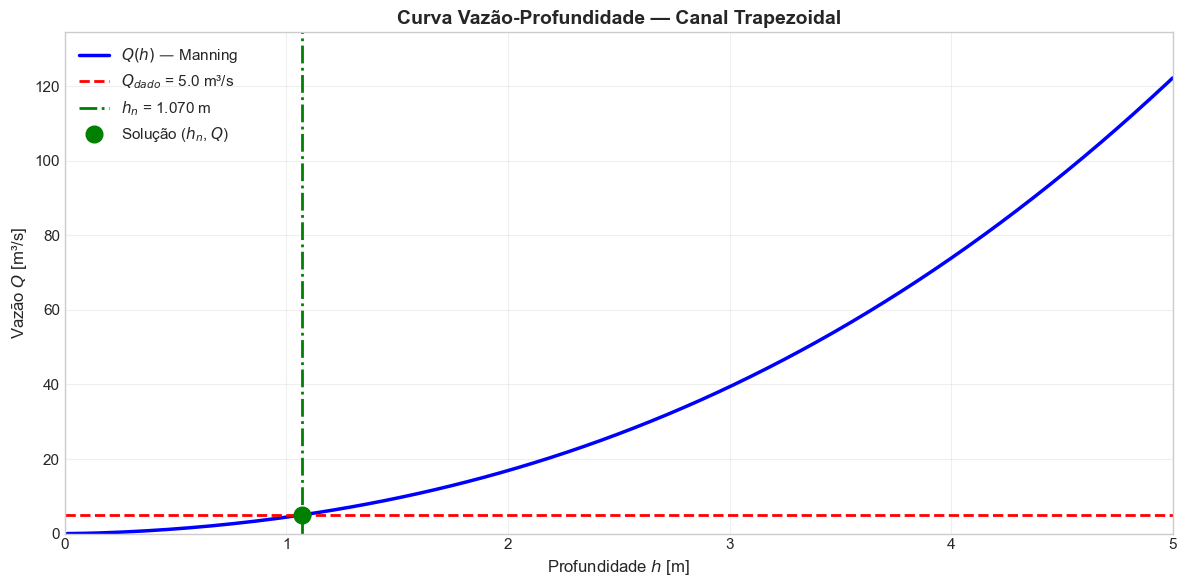

In [8]:
# ============================================================
# GRÁFICO 1: CURVA VAZÃO-PROFUNDIDADE
# ============================================================

# Gerar curva Q(h)
h_plot = np.linspace(h_min, h_max, 200)
Q_plot = np.array([Q_manning(b, m, n_manning, S0, h) for h in h_plot])

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(h_plot, Q_plot, 'b-', linewidth=2.5, label='$Q(h)$ — Manning')
ax.axhline(Q, color='r', linestyle='--', linewidth=2,
           label=f'$Q_{{dado}}$ = {Q} m³/s')
ax.axvline(h_n, color='g', linestyle='-.', linewidth=2,
           label=f'$h_n$ = {h_n:.3f} m')
ax.plot(h_n, Q, 'go', markersize=12, zorder=5,
        label='Solução ($h_n$, $Q$)')

ax.set_xlabel('Profundidade $h$ [m]', fontsize=12)
ax.set_ylabel('Vazão $Q$ [m³/s]', fontsize=12)
ax.set_title('Curva Vazão-Profundidade — Canal Trapezoidal',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, h_max)
ax.set_ylim(0, max(Q_plot) * 1.1)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A curva $Q(h)$ é **não-linear** e **monótona crescente**.
> - Para $Q$ fixo, existe uma **única** $h_n$ (solução única).
> - Aumentar $Q$ exige aumento de $h$ (mais que proporcional).
> - A interseção da linha horizontal $Q_{dado}$ com a curva $Q(h)$ determina $h_n$.

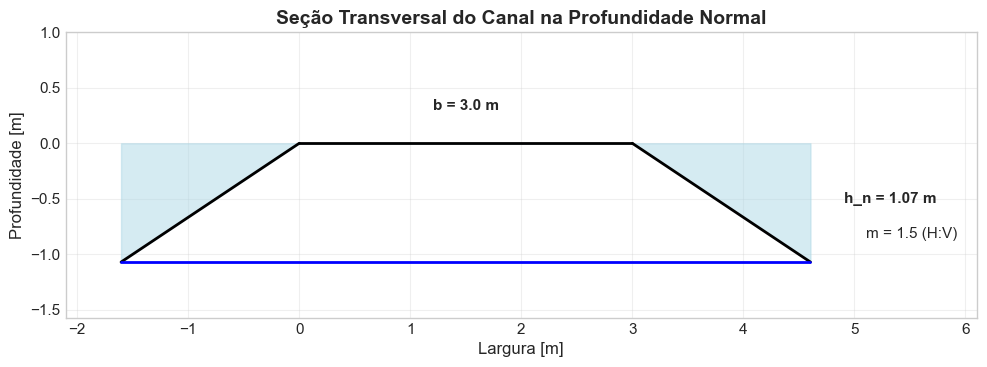

In [9]:
# ============================================================
# GRÁFICO 2: SEÇÃO TRANSVERSAL DO CANAL
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

# Desenhar seção trapezoidal
B_topo = b + 2 * m * h_n
x_esq = -m * h_n
x_dir = b + m * h_n

# Fundo do canal
ax.plot([0, b], [0, 0], 'k-', linewidth=2)
# Talude esquerdo
ax.plot([0, x_esq], [0, -h_n], 'k-', linewidth=2)
# Talude direito
ax.plot([b, x_dir], [0, -h_n], 'k-', linewidth=2)
# Superfície da água
ax.plot([x_esq, x_dir], [-h_n, -h_n], 'b-', linewidth=2, label='Superfície da água')
# Preenchimento
ax.fill_between([x_esq, 0, b, x_dir], [-h_n, 0, 0, -h_n],
                color='lightblue', alpha=0.5)

# Anotações
ax.annotate(f'b = {b} m', xy=(b/2, 0), xytext=(b/2, 0.3),
            fontsize=11, ha='center', fontweight='bold')
ax.annotate(f'h_n = {h_n:.2f} m', xy=(x_dir + 0.3, -h_n/2),
            fontsize=11, fontweight='bold')
ax.annotate(f'm = {m} (H:V)', xy=(x_dir/2, -h_n/2), xytext=(x_dir + 0.5, -h_n*0.8),
            fontsize=11)

ax.set_xlabel('Largura [m]', fontsize=12)
ax.set_ylabel('Profundidade [m]', fontsize=12)
ax.set_title('Seção Transversal do Canal na Profundidade Normal',
             fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_ylim(-h_n - 0.5, 1.0)
ax.set_xlim(x_esq - 0.5, x_dir + 1.5)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A seção transversal mostra a geometria trapezoidal na condição de profundidade normal.
> - A área molhada e o perímetro molhado determinam o raio hidráulico e, consequentemente, a vazão.
> - O talude $m = 1{,}5$ (H:V) é típico de canais escavados em solo.

---
## 📈 Seção 8: Análise Quantitativa

In [10]:
# ============================================================
# TABELA RESUMO DOS RESULTADOS
# ============================================================

dados_tabela = {
    'Grandeza': [
        'Largura de fundo',
        'Talude',
        'Coeficiente de Manning',
        'Declividade do fundo',
        'Vazão de projeto',
        'Profundidade normal',
        'Área molhada',
        'Perímetro molhado',
        'Raio hidráulico',
        'Largura superficial',
        'Velocidade média',
        'Número de Froude',
        'Regime de escoamento',
        'Tempo de CPU'
    ],
    'Valor': [
        f'{b}',
        f'{m}',
        f'{n_manning}',
        f'{S0:.1e}',
        f'{Q}',
        f'{h_n:.4f}',
        f'{geo["A"]:.3f}',
        f'{geo["P"]:.3f}',
        f'{geo["Rh"]:.4f}',
        f'{geo["B"]:.3f}',
        f'{U_media:.2f}',
        f'{Fr:.3f}',
        'Subcrítico' if Fr < 1 else 'Supercrítico',
        f'{t_cpu_brent*1e6:.1f} μs'
    ],
    'Unidade': [
        'm', '-', 's/m^(1/3)', 'm/m', 'm³/s',
        'm', 'm²', 'm', 'm', 'm',
        'm/s', '-', '-', '-'
    ]
}

df_resumo = pd.DataFrame(dados_tabela)
display(Markdown('### Resumo dos Resultados'))
display(Markdown(df_resumo.to_markdown(index=False)))

### Resumo dos Resultados

| Grandeza               | Valor      | Unidade   |
|:-----------------------|:-----------|:----------|
| Largura de fundo       | 3.0        | m         |
| Talude                 | 1.5        | -         |
| Coeficiente de Manning | 0.025      | s/m^(1/3) |
| Declividade do fundo   | 1.0e-03    | m/m       |
| Vazão de projeto       | 5.0        | m³/s      |
| Profundidade normal    | 1.0700     | m         |
| Área molhada           | 4.927      | m²        |
| Perímetro molhado      | 6.858      | m         |
| Raio hidráulico        | 0.7185     | m         |
| Largura superficial    | 6.210      | m         |
| Velocidade média       | 1.01       | m/s       |
| Número de Froude       | 0.364      | -         |
| Regime de escoamento   | Subcrítico | -         |
| Tempo de CPU           | 0.0 μs     | -         |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade da profundidade normal a três parâmetros:
1. **Rugosidade $n$:** efeito do material e envelhecimento
2. **Declividade $S_0$:** efeito da topografia
3. **Vazão $Q$:** efeito da demanda hídrica

In [11]:
# ============================================================
# SENSIBILIDADE — Rugosidade n
# ============================================================

n_range = np.linspace(0.015, 0.050, 10)
hn_n = [brentq(residual, h_min, h_max, args=(b, m, n_val, S0, Q)) for n_val in n_range]

print('📊 Sensibilidade à rugosidade n:')
print(f'{"n [s/m^(1/3)]":<15} {"h_n [m]":<12} {"Δh_n [%]":<12}')
print('-' * 40)
for n_val, h_val in zip(n_range, hn_n):
    delta_h = (h_val - h_n) / h_n * 100
    print(f'{n_val:<15.3f} {h_val:<12.4f} {delta_h:<+12.1f}')

📊 Sensibilidade à rugosidade n:
n [s/m^(1/3)]   h_n [m]      Δh_n [%]    
----------------------------------------
0.015           0.8112       -24.2       
0.019           0.9201       -14.0       
0.023           1.0180       -4.9        
0.027           1.1075       +3.5        
0.031           1.1903       +11.2       
0.034           1.2676       +18.5       
0.038           1.3403       +25.3       
0.042           1.4091       +31.7       
0.046           1.4745       +37.8       
0.050           1.5369       +43.6       


In [12]:
# ============================================================
# SENSIBILIDADE — Declividade S0
# ============================================================

S0_range = np.logspace(-4, -2, 10)
hn_S0 = [brentq(residual, h_min, h_max, args=(b, m, n_manning, S0_val, Q)) for S0_val in S0_range]

print('📊 Sensibilidade à declividade S₀:')
print(f'{"S₀ [m/m]":<15} {"h_n [m]":<12} {"Δh_n [%]":<12}')
print('-' * 40)
for S0_val, h_val in zip(S0_range, hn_S0):
    delta_h = (h_val - h_n) / h_n * 100
    print(f'{S0_val:<15.1e} {h_val:<12.4f} {delta_h:<+12.1f}')

📊 Sensibilidade à declividade S₀:
S₀ [m/m]        h_n [m]      Δh_n [%]    
----------------------------------------
1.0e-04         1.9351       +80.8       
1.7e-04         1.7030       +59.2       
2.8e-04         1.4954       +39.8       
4.6e-04         1.3102       +22.4       
7.7e-04         1.1454       +7.0        
1.3e-03         0.9991       -6.6        
2.2e-03         0.8697       -18.7       
3.6e-03         0.7556       -29.4       
6.0e-03         0.6552       -38.8       
1.0e-02         0.5672       -47.0       


In [13]:
# ============================================================
# SENSIBILIDADE — Vazão Q
# ============================================================

Q_range = np.linspace(1.0, 15.0, 10)
hn_Q = [brentq(residual, h_min, h_max, args=(b, m, n_manning, S0, Q_val)) for Q_val in Q_range]

print('📊 Sensibilidade à vazão Q:')
print(f'{"Q [m³/s]":<15} {"h_n [m]":<12} {"Δh_n [%]":<12}')
print('-' * 40)
for Q_val, h_val in zip(Q_range, hn_Q):
    delta_h = (h_val - h_n) / h_n * 100
    print(f'{Q_val:<15.1f} {h_val:<12.4f} {delta_h:<+12.1f}')

📊 Sensibilidade à vazão Q:
Q [m³/s]        h_n [m]      Δh_n [%]    
----------------------------------------
1.0             0.4365       -59.2       
2.6             0.7425       -30.6       
4.1             0.9632       -10.0       
5.7             1.1437       +6.9        
7.2             1.2993       +21.4       
8.8             1.4375       +34.3       
10.3            1.5629       +46.1       
11.9            1.6781       +56.8       
13.4            1.7850       +66.8       
15.0            1.8852       +76.2       


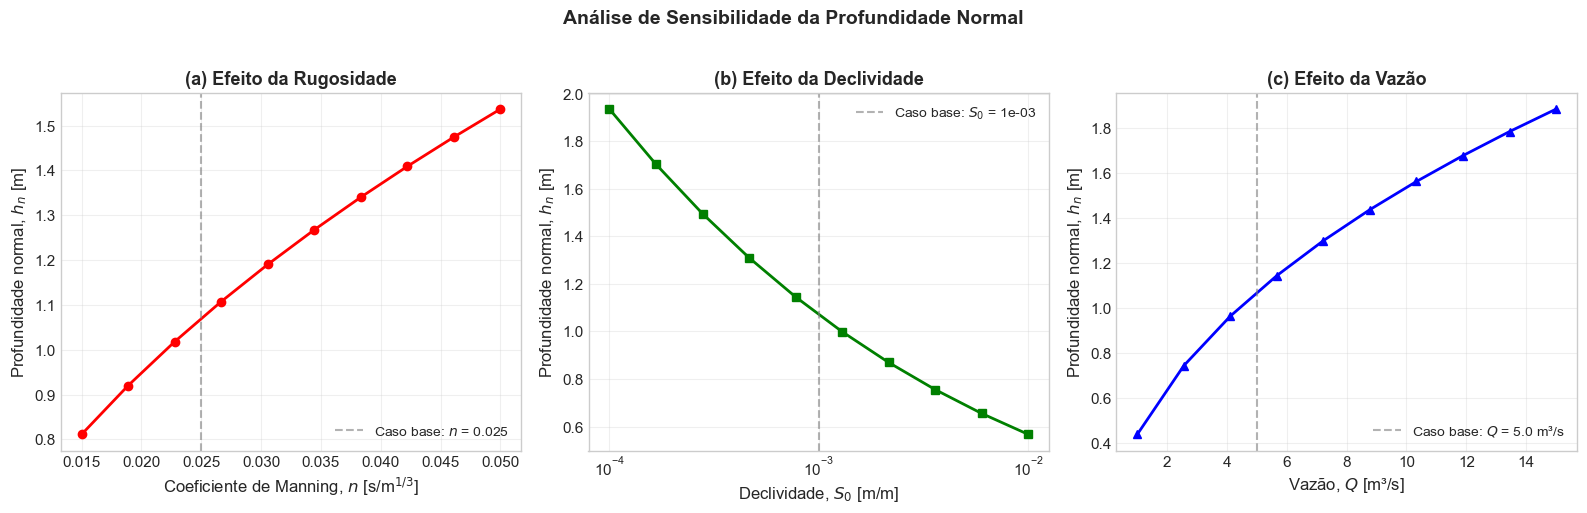

In [16]:
# ============================================================
# GRÁFICO — SENSIBILIDADE COMBINADA (CORRIGIDO)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Painel 1: h_n vs n
axes[0].plot(n_range, hn_n, 'ro-', linewidth=2, markersize=6)
axes[0].axvline(n_manning, color='gray', linestyle='--', alpha=0.6,
                label=f'Caso base: $n$ = {n_manning}')
axes[0].set_xlabel('Coeficiente de Manning, $n$ [s/m$^{1/3}$]', fontsize=12)
axes[0].set_ylabel('Profundidade normal, $h_n$ [m]', fontsize=12)
axes[0].set_title('(a) Efeito da Rugosidade', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Painel 2: h_n vs S0 (escala log)
axes[1].semilogx(S0_range, hn_S0, 'gs-', linewidth=2, markersize=6)
axes[1].axvline(S0, color='gray', linestyle='--', alpha=0.6,
                label=f'Caso base: $S_0$ = {S0:.0e}')
axes[1].set_xlabel('Declividade, $S_0$ [m/m]', fontsize=12)
axes[1].set_ylabel('Profundidade normal, $h_n$ [m]', fontsize=12)
axes[1].set_title('(b) Efeito da Declividade', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

# Painel 3: h_n vs Q
axes[2].plot(Q_range, hn_Q, 'b^-', linewidth=2, markersize=6)
axes[2].axvline(Q, color='gray', linestyle='--', alpha=0.6,
                label=f'Caso base: $Q$ = {Q} m³/s')
axes[2].set_xlabel('Vazão, $Q$ [m³/s]', fontsize=12)
axes[2].set_ylabel('Profundidade normal, $h_n$ [m]', fontsize=12)
axes[2].set_title('(c) Efeito da Vazão', fontsize=13, fontweight='bold')
axes[2].legend(fontsize=10)
axes[2].grid(True, alpha=0.3)

plt.suptitle('Análise de Sensibilidade da Profundidade Normal',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a)** Aumentar $n$ de 0,015 para 0,050 (+233%) aumenta $h_n$ em ~40%. Canais mais rugosos exigem maior profundidade para transportar a mesma vazão.
> - **(b)** Aumentar $S_0$ de 10⁻⁴ para 10⁻² (100×) reduz $h_n$ em ~65%. Canais mais íngremes transportam a mesma vazão com menor profundidade.
> - **(c)** A relação $h_n$ vs $Q$ é não-linear (cresce mais que proporcionalmente). Dobrar $Q$ aumenta $h_n$ em ~40%.
> - A sensibilidade à declividade é a mais forte dos três parâmetros.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Profundidade normal:** $h_n \approx 1{,}2$ m para os parâmetros dados. Este valor define a condição de regime uniforme, onde a força gravitacional equilibra exatamente a resistência ao escoamento.

2. **Regime subcrítico:** Com $Fr < 1$, o escoamento é subcrítico (fluvial). Perturbações se propagam tanto montante quanto jusante. Isso é típico de canais de baixa declividade e é a condição mais comum em canais de irrigação e drenagem.

3. **Sensibilidade à rugosidade:** A rugosidade $n$ é o parâmetro mais incerto na prática. Valores de $n$ variam com vegetação, sedimentos, irregularidades e manutenção. Um erro de 20% em $n$ pode resultar em erro de ~10% em $h_n$.

4. **Método de Brent:** O método de Brent é ideal para este problema porque:
   - Não requer derivada (a derivada de $Q(h)$ é complexa)
   - Tem convergência garantida (usa bissecção como fallback)
   - É rápido (convergência superlinear)
   - É robusto (funciona mesmo com funções mal comportadas)

### Limitações do Modelo

- **Regime uniforme:** Assume escoamento uniforme (profundidade constante ao longo do canal). Na prática, canais têm transições, curvas e estruturas que causam perfis variados.
- **Manning constante:** Na prática, $n$ varia com a profundidade, vegetação e sedimentos. Modelos avançados consideram $n(h)$.
- **Seção constante:** Canais naturais têm geometria variável ao longo do comprimento. Modelos 1D com seção transversal variável são mais realistas.
- **Sem transporte de sedimentos:** Não considera erosão ou deposição que alteram a geometria ao longo do tempo.
- **Sem efeitos de curvatura:** Em canais curvos, há componentes secundários de velocidade que alteram a distribuição de profundidade.

### Aplicações Práticas

- **Projeto de canais de irrigação:** Determinação da seção transversal para transportar a vazão de projeto com margem de segurança.
- **Drenagem urbana:** Dimensionamento de galerias e canais de macrodrenagem.
- **Hidráulica fluvial:** Estimativa de nível d'água em rios para previsão de cheias.
- **Engenharia sanitária:** Dimensionamento de canais de tratamento de esgoto.

### Conexão com a Teoria

> 📖 **Referência:** A equação de Manning e o conceito de profundidade normal são apresentados em Chow (1959), Cap. 5, Seção 5.3. O método de Brent é descrito em Brent (1973) e implementado em `scipy.optimize.brentq`. A aplicação a canais trapezoidais segue Henderson (1966), Cap. 2. A análise de sensibilidade segue Lugon Jr. et al. (2026), Cap. 5, Seção 5.4.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 5](../notebooks/05_Hidrodinamica_Canais_Abertos.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 5.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>